# Python–MATLAB comparison through line 167

This notebook uses the five-cavity L-band example from the KlyC User Manual. It evaluates the translated Python code in the same order as `KLJCmainsv22.m`, exports all 45 MATLAB inputs, and saves a checkpoint for numerical comparison.

In [1]:
from pathlib import Path
import sys

# Computation modules
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat, savemat

# Paths of all the possible project directories
current_directory = Path.cwd().resolve()
possible_project_directories = [
    current_directory,
    current_directory / "pyKlyC",
    current_directory.parent,
]
project_directory = next(
    (path for path in possible_project_directories if (path / "src").exists()),
    None,
)

notebook_directory = project_directory / "Notebooks"

sys.path.insert(0, str(project_directory / "src"))

# Importing modules from the project
from constants import c, esign, eta0, etom, etom_signed, mu01, mu0
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.cavity_field_map import CavityFieldMap
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.beam_state import BeamState
from solver.cavity_fields import CavityFields
from solver.cavity_state import CavityState
from solver.grid import GridParameters
from solver.reference import ReferenceParameters
from solver.space_charge import SpaceChargeState

np.set_printoptions(precision=12, linewidth=160)

In [2]:
# Functions just to print properly variables for checking
def show_variable(name, value):
    array = np.asarray(value)
    if array.ndim == 0:
        print(f"{name}: {array.item()!r} ({array.dtype})")
    else:
        print(f"{name}: shape={array.shape}, dtype={array.dtype}")
        if array.size <= 20:
            print(array)
        elif array.ndim == 1:
            print("first values:", array[:5])
            print("last values: ", array[-5:])
        else:
            print("first rows:")
            print(array[:3])
            print("last rows:")
            print(array[-3:])
    print()


def show_object(obj):
    for name in obj.__dataclass_fields__:
        show_variable(name, getattr(obj, name))

## Test inputs and MATLAB export

The beam, cavities, and accuracy settings come from the five-cavity example in the KlyC User Manual. `z0`, `L`, `rcv`, and the Gaussian field-map limits are reconstructed using the rules in the KlyC application. Python keeps `Y0` zero-based; the exported MATLAB file contains the corresponding one-based indices.

In [3]:
Nc = 5
Ns = 8
Nz = 256
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
factor = 1.0
factorregion = 10.0
fillfactor = 1.0
DCSPfactor = 1.0
iterfactor = 0.5

Nbeam = 1
rm2 = 6.0
rm1 = 0.0
rc = 10.0
xb = 0.0
yb = 0.0
xd = 0.0
yd = 0.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
f = 1.0
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
Pin = np.full(Nc, 60.0)
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)

RtoQ = np.array([182.8959, 116.9999, 102.0570, 123.6318, 180.3864])
M = np.array([0.9225, 0.8930, 0.8192, 0.9518, 0.9325])

beam_speed_ratio = np.sqrt(
    1.0 - (1.0 + etom * Ut[0] * 1.0e3 / c**2) ** -2
)
w0_for_maps = 2.0 * np.pi * f0 * 1.0e9
gaussian_k = (
    0.5
    * w0_for_maps
    / beam_speed_ratio
    / c
    / np.sqrt(-np.log(M))
)
field_half_width = 3.0 / gaussian_k * 1.0e3

extension_over_rc = 2.0
z0 = np.min(zshift - field_half_width) - 2.0 * rc
L = (
    np.max(zshift + field_half_width)
    - z0
    + (4.0 + extension_over_rc) * rc
)

cavity_names = [f"guide_cavity_{k + 1}" for k in range(Nc)]
cavityname = " ".join(cavity_names)
tn1 = t0.copy()
Y0 = np.arange(Nt)
evolutionmethod = np.array([0.005, 2.0])
figuredisp = "off"
moviedisp = np.array([0, 0, 0, 0, 1])
GIFpara = np.array([64.0, -0.2, 1.0, 0.0, 3.0 * rc, 0.0])
Npin = 10
kai = np.zeros((Nc, Nc), dtype=complex)
rcv = np.vstack((
    np.concatenate(([z0 - rc], zshift, [z0 + L + rc])),
    np.ones(Nc + 2),
))

# Just to see varaitions in the pipe
# rcv[1, 3] = 1.2
# rcv[1, 4] = 1.2

mono = 1

matlab_inputs = {
    "Nc": Nc,
    "Ns": Ns,
    "Nz": Nz,
    "Nlimit": Nlimit,
    "Ntimes": Ntimes,
    "Rlimit": Rlimit,
    "factor": factor,
    "factorregion": factorregion,
    "fillfactor": fillfactor,
    "DCSPfactor": DCSPfactor,
    "iterfactor": iterfactor,
    "z0": z0,
    "L": L,
    "Nbeam": Nbeam,
    "rm2": rm2,
    "rm1": rm1,
    "rc": rc,
    "xb": xb,
    "yb": yb,
    "xd": xd,
    "yd": yd,
    "Nt": Nt,
    "t0": t0,
    "f": f,
    "Ut": Ut,
    "Izt": Izt,
    "type": type,
    "nh": nh,
    "f0": f0,
    "Qext": Qext,
    "Qin": Qin,
    "zshift": zshift,
    "Pin": Pin,
    "gaman": gaman,
    "cavityname": cavityname,
    "tn1": tn1,
    "Y0": Y0 + 1,
    "evolutionmethod": evolutionmethod,
    "figuredisp": figuredisp,
    "moviedisp": moviedisp,
    "GIFpara": GIFpara,
    "Npin": Npin,
    "kai": kai,
    "rcv": rcv,
    "mono": mono,
}

matlab_input_file = notebook_directory / "matlab_test_inputs.mat"
savemat(matlab_input_file, matlab_inputs, oned_as="row")
print(f"Saved all MATLAB inputs to {matlab_input_file}")

numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit, Ntimes=Ntimes,
    Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=evolutionmethod,
)
beam = BeamParameters(
    Nbeam=Nbeam, rm2=rm2, rm1=rm1, rc=rc,
    xb=xb, yb=yb, xd=xd, yd=yd, Nt=Nt,
    t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)

show_variable("z0", z0)
show_variable("L", L)
show_variable("rcv", rcv)

Saved all MATLAB inputs to C:\Users\lsito\Desktop\PyKlyC\pyKlyC\Notebooks\matlab_test_inputs.mat
z0: -74.7333001770784 (float64)

L: 2915.6777338903767 (float64)

rcv: shape=(2, 7), dtype=float64
[[-8.473330017708e+01  0.000000000000e+00  4.800000000000e+02  1.630000000000e+03  2.400000000000e+03  2.730000000000e+03  2.850944433713e+03]
 [ 1.000000000000e+00  1.000000000000e+00  1.000000000000e+00  1.000000000000e+00  1.000000000000e+00  1.000000000000e+00  1.000000000000e+00]]



## Guide-based Gaussian cavity field maps

KlyC reconstructs these normalized local maps from the guide's cavity `R/Q` and coupling `M`. Each cavity map contains 201 points centered on the cavity.

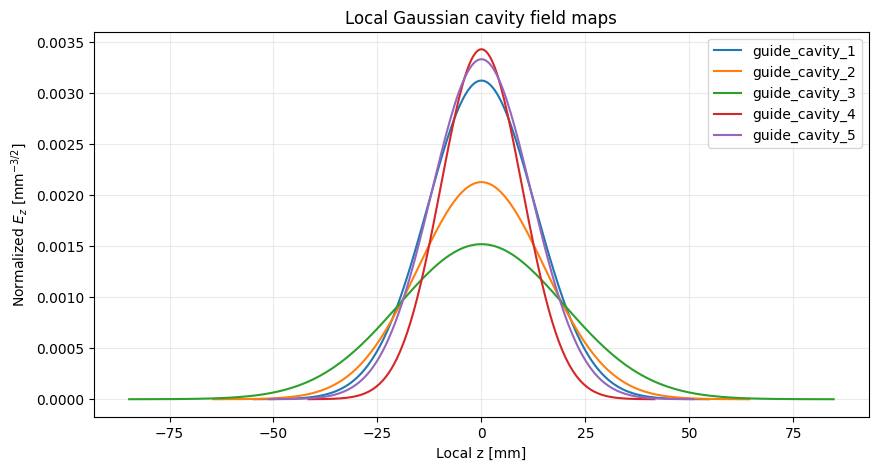

In [4]:
field_maps = CavityFieldMap.from_circuit_parameters(
    cavityname=cavities.names,
    f0=f0,
    RtoQ=RtoQ,
    M=M,
    s=beam_speed_ratio,
)

fig, ax = plt.subplots(figsize=(10, 5))

for name, field_map in field_maps.items():
    ax.plot(
        field_map.z_mm,
        field_map.e_z,
        label=Path(name).name,
    )

ax.set_xlabel("Local z [mm]")
ax.set_ylabel(r"Normalized $E_z$ [mm$^{-3/2}$]")
ax.set_title("Local Gaussian cavity field maps")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## Constants and reference variables

In [5]:
for name, value in {
    "c": c,
    "etom_signed": etom_signed,
    "etom": etom,
    "esign": esign,
    "eta0": eta0,
    "mu01": mu01,
    "mu0": mu0,
}.items():
    show_variable(name, value)

reference = ReferenceParameters.calculate_reference_parameters(beam)
show_object(reference)

c: 299792458.0 (float64)

etom_signed: -175880000000.0 (float64)

etom: 175880000000.0 (float64)

esign: 1.0 (float64)

eta0: 376.73031346177066 (float64)

mu01: 2.40483 (float64)

mu0: shape=(5,), dtype=float64
[ 2.40483  5.52008  8.65373 11.79153 14.93092]

Iz0: -16.0 (float64)

I0: 16.0 (float64)

U0: 180.0 (float64)

s: 0.6731458398741619 (float64)

vetoc: shape=(128,), dtype=float64
first values: [0.673145839874 0.673145839874 0.673145839874 0.673145839874 0.673145839874]
last values:  [0.673145839874 0.673145839874 0.673145839874 0.673145839874 0.673145839874]

vn1: shape=(128,), dtype=float64
first values: [1. 1. 1. 1. 1.]
last values:  [1. 1. 1. 1. 1.]

gama: 1.3522472053456789 (float64)



## Frequency and longitudinal-grid variables

In [ ]:
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)
show_object(grid)

Nesz_matlab = grid.Nesz.copy()
Nesz_matlab[:, 0] += 1
show_variable("Nesz_matlab", Nesz_matlab)

`Nesz` stores zero-based Python slice bounds with an exclusive stop. `Nesz_matlab` contains the equivalent one-based, inclusive MATLAB indices.

## Longitudinal geometry

This cross-section shows the complete longitudinal grid, the beam and tunnel radii, and a schematic cavity contour based on each Gaussian field extent. The contour is for visualization and is not a physical cavity-wall model.

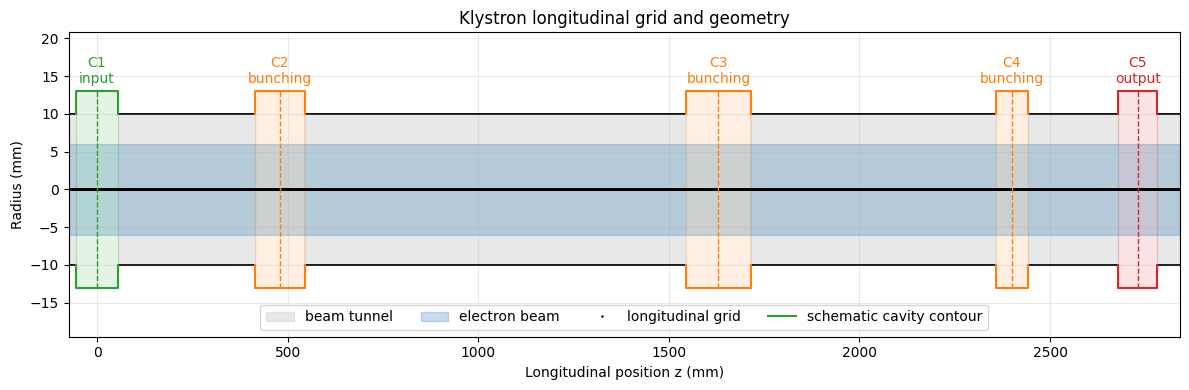

In [7]:
cavity_labels = {0: "input", 1: "bunching", -1: "output"}
cavity_colors = {0: "tab:green", 1: "tab:orange", -1: "tab:red"}

cavity_plot_radius = 1.3 * rc
inside_cavity = np.zeros(len(grid.zi), dtype=bool)
for k in range(Nc):
    left = zshift[k] - field_half_width[k]
    right = zshift[k] + field_half_width[k]
    inside_cavity |= (grid.zi >= left) & (grid.zi <= right)

fig, ax = plt.subplots(figsize=(12, 4))

ax.fill_between(
    grid.zi,
    -grid.rcvs,
    grid.rcvs,
    color="lightgray",
    alpha=0.5,
    where=~inside_cavity,
    label="beam tunnel",
)
tunnel_wall = np.ma.masked_where(inside_cavity, grid.rcvs)
ax.plot(grid.zi, tunnel_wall, color="black", linewidth=1.2)
ax.plot(grid.zi, -tunnel_wall, color="black", linewidth=1.2)

ax.fill_between(
    grid.zi,
    -beam.rm2,
    beam.rm2,
    color="tab:blue",
    alpha=0.25,
    label="electron beam",
)
ax.plot(
    grid.zi,
    np.zeros_like(grid.zi),
    linestyle="none",
    marker=".",
    markersize=1.5,
    color="black",
    label="longitudinal grid",
)

for k in range(Nc):
    color = cavity_colors[type[k]]
    left = zshift[k] - field_half_width[k]
    right = zshift[k] + field_half_width[k]
    ax.fill_between(
        [left, right],
        -cavity_plot_radius,
        cavity_plot_radius,
        color=color,
        alpha=0.12,
    )
    ax.plot(
        [left, left, right, right],
        [rc, cavity_plot_radius, cavity_plot_radius, rc],
        color=color,
        linewidth=1.5,
        label="schematic cavity contour" if k == 0 else None,
    )
    ax.plot(
        [left, left, right, right],
        [-rc, -cavity_plot_radius, -cavity_plot_radius, -rc],
        color=color,
        linewidth=1.5,
    )
    ax.plot(
        [zshift[k], zshift[k]],
        [-cavity_plot_radius, cavity_plot_radius],
        color=color,
        linewidth=1.0,
        linestyle="--",
    )
    ax.text(
        zshift[k],
        1.05 * cavity_plot_radius,
        f"C{k + 1}\n{cavity_labels[type[k]]}",
        color=color,
        horizontalalignment="center",
        verticalalignment="bottom",
    )

ax.set_xlim(grid.zi[0], grid.zi[-1])
ax.set_ylim(-1.5 * cavity_plot_radius, 1.6 * cavity_plot_radius)
ax.set_xlabel("Longitudinal position z (mm)")
ax.set_ylabel("Radius (mm)")
ax.set_title("Klystron longitudinal grid and geometry")
ax.grid(alpha=0.25)
ax.legend(loc="lower center", ncol=4)
plt.tight_layout()
plt.show()

## Cavity-field variables

ez: shape=(3699, 5), dtype=float64
first rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
last rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

C3: shape=(3699, 5), dtype=float64
first rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
last rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

vpz: shape=(3699, 5), dtype=float64
first rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
last rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

alfaz: shape=(3699, 5), dtype=float64
first rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
last rows:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]



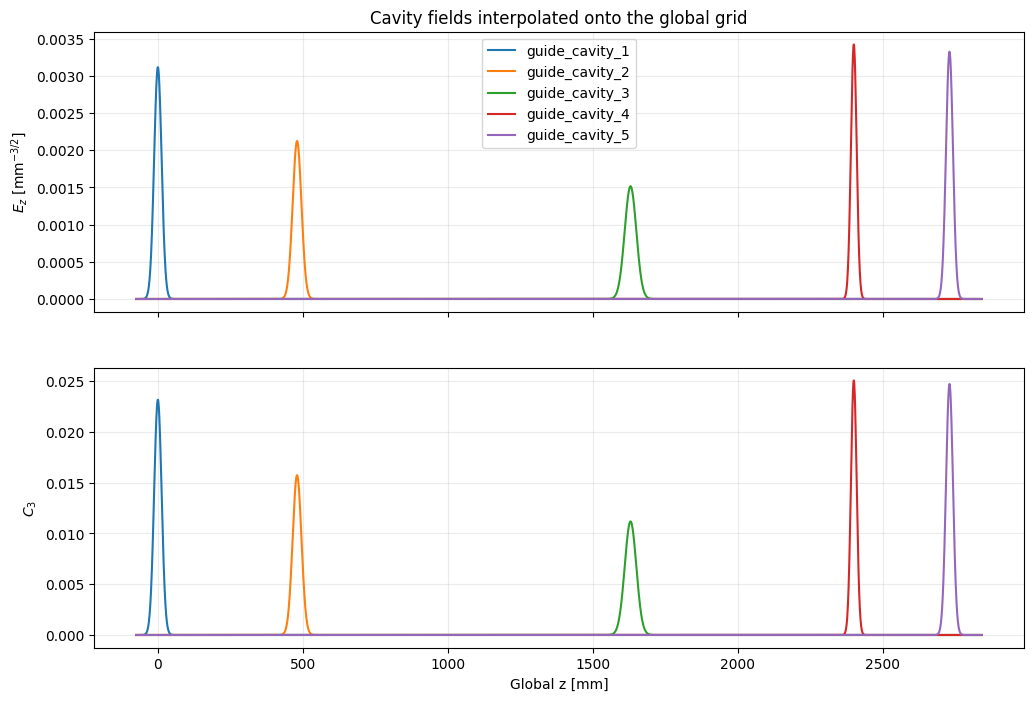

In [8]:
cavity_fields = CavityFields.calculate(
    numerical, cavities, grid, reference, field_maps
)
show_object(cavity_fields)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for k, name in enumerate(cavities.names):
    label = Path(name).name
    axes[0].plot(grid.zi, cavity_fields.ez[:, k], label=label)
    axes[1].plot(grid.zi, cavity_fields.C3[:, k], label=label)

axes[0].set_ylabel(r"$E_z$ [mm$^{-3/2}$]")
axes[0].set_title("Cavity fields interpolated onto the global grid")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].set_xlabel("Global z [mm]")
axes[1].set_ylabel(r"$C_3$")
axes[1].grid(alpha=0.25)

plt.show()

## Initial cavity state

`Pinflag`, positive `Pin`, and normalized `Vin` reproduce MATLAB lines 183–188. The voltage vectors and equivalent-circuit arrays are initialized here and will be filled by the later circuit update.

In [ ]:
cavity_state = CavityState.initialize(
    numerical, cavities, beam, reference
)
show_object(cavity_state)

cavity_numbers = np.arange(1, numerical.Nc + 1)
power_colors = np.where(
    cavity_state.Pinflag < 0.0, "tab:red", "tab:blue"
)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].bar(cavity_numbers, cavity_state.Pin, color=power_colors)
axes[0].set_ylabel(r"$P_{in}$ [W]")
axes[0].set_title("Positive cavity input-power magnitudes")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(cavity_numbers, cavity_state.Vin, color=power_colors)
axes[1].set_xlabel("Cavity number")
axes[1].set_ylabel(r"$V_{in}$")
axes[1].set_title("Normalized incident waveguide voltages")
axes[1].set_xticks(cavity_numbers)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Initial beam-state variables

Iz: shape=(3699, 8), dtype=complex128
first rows:
[[ 1.110223024625e-16-5.551115123126e-17j  2.125036258072e-17-3.469446951954e-17j -0.000000000000e+00-1.179611963664e-16j
   4.336808689942e-17-1.526556658860e-16j  5.551115123126e-17-1.665334536938e-16j -6.591949208712e-17-3.382710778155e-17j
   4.163336342344e-17+6.938893903907e-17j  1.214306433184e-16-3.215665005006e-16j]
 [ 1.110223024625e-16-5.551115123126e-17j  2.125036258072e-17-3.469446951954e-17j -0.000000000000e+00-1.179611963664e-16j
   4.336808689942e-17-1.526556658860e-16j  5.551115123126e-17-1.665334536938e-16j -6.591949208712e-17-3.382710778155e-17j
   4.163336342344e-17+6.938893903907e-17j  1.214306433184e-16-3.215665005006e-16j]
 [ 1.110223024625e-16-5.551115123126e-17j  2.125036258072e-17-3.469446951954e-17j -0.000000000000e+00-1.179611963664e-16j
   4.336808689942e-17-1.526556658860e-16j  5.551115123126e-17-1.665334536938e-16j -6.591949208712e-17-3.382710778155e-17j
   4.163336342344e-17+6.938893903907e-17j  1.2143064

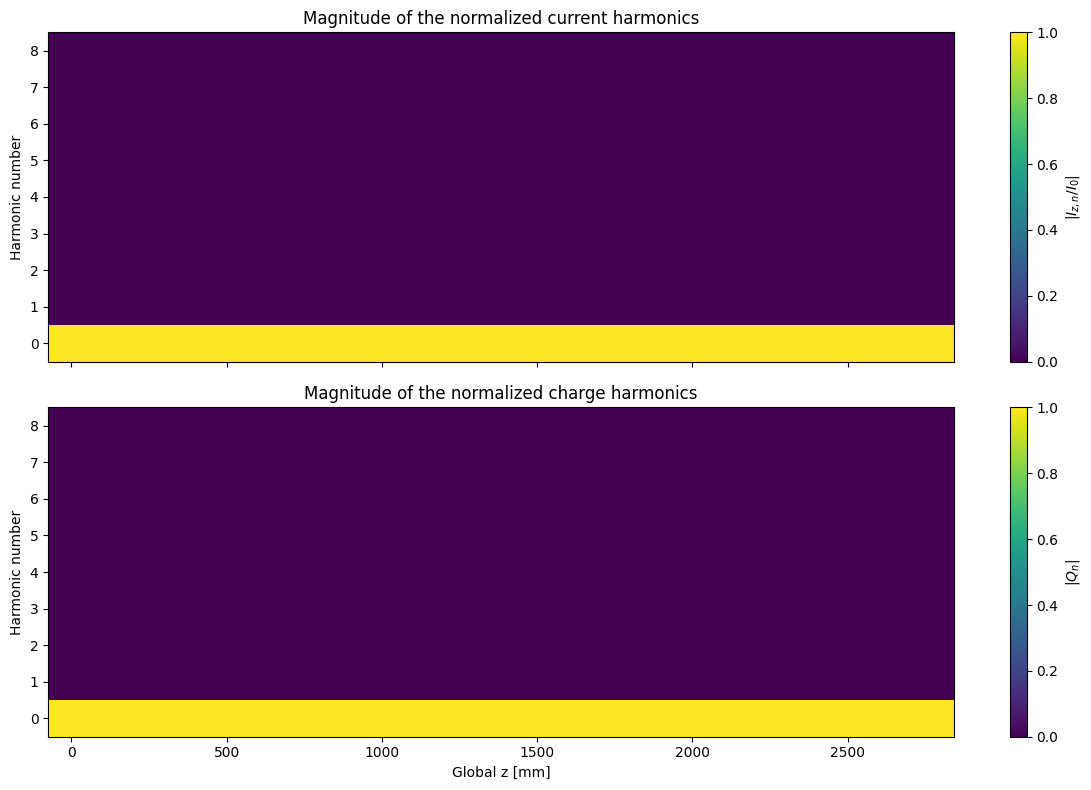

In [9]:
state = BeamState.initialize(numerical, beam, grid, reference)
show_object(state)

harmonics = np.arange(numerical.Ns + 1)
Iz = np.column_stack((state.IzDC, state.Iz))
QQ = np.column_stack((state.QQDC, state.QQ))
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

current_plot = axes[0].pcolormesh(
    grid.zi,
    harmonics,
    np.abs(Iz).T,
    shading="auto",
)
axes[0].set_ylabel("Harmonic number")
axes[0].set_title("Magnitude of the normalized current harmonics")
fig.colorbar(current_plot, ax=axes[0], label=r"$|I_{z,n}/I_0|$")

charge_plot = axes[1].pcolormesh(
    grid.zi,
    harmonics,
    np.abs(QQ).T,
    shading="auto",
)
axes[1].set_xlabel("Global z [mm]")
axes[1].set_ylabel("Harmonic number")
axes[1].set_title("Magnitude of the normalized charge harmonics")
fig.colorbar(charge_plot, ax=axes[1], label=r"$|Q_n|$")

plt.tight_layout()
plt.show()

## Initial cavity equivalent-circuit solution

The normal-klystron circuit update assembles `Mc` and `B` from the initial current harmonics and solves for `Vnp` and `Vnc`. The power-ramp factor is one at this checkpoint.

In [ ]:
cavity_state.solve(
    numerical, cavities, cavity_fields, beam, state, grid
)

show_variable("Mc", cavity_state.Mc)
show_variable("B", cavity_state.B)
show_variable("Vnp", cavity_state.Vnp)
show_variable("Vnc", cavity_state.Vnc)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

Mc_magnitude = axes[0, 0].imshow(
    np.abs(cavity_state.Mc), aspect="auto", cmap="viridis"
)
axes[0, 0].set_title(r"$|M_c|$")
axes[0, 0].set_xlabel("Unknown column")
axes[0, 0].set_ylabel("Equation row")
fig.colorbar(Mc_magnitude, ax=axes[0, 0])

Mc_phase = axes[0, 1].imshow(
    np.angle(cavity_state.Mc), aspect="auto", cmap="twilight",
    vmin=-np.pi, vmax=np.pi,
)
axes[0, 1].set_title(r"$\arg(M_c)$")
axes[0, 1].set_xlabel("Unknown column")
axes[0, 1].set_ylabel("Equation row")
fig.colorbar(Mc_phase, ax=axes[0, 1], label="Phase [rad]")

equation_numbers = np.arange(1, len(cavity_state.B) + 1)
axes[1, 0].bar(equation_numbers, np.abs(cavity_state.B))
axes[1, 0].set_title(r"Excitation vector $|B|$")
axes[1, 0].set_xlabel("Equation number")
axes[1, 0].set_ylabel(r"$|B|$")
axes[1, 0].grid(axis="y", alpha=0.25)

width = 0.35
axes[1, 1].bar(
    cavity_numbers - width / 2.0, np.abs(cavity_state.Vnp),
    width=width, label=r"$|V_{np}|$",
)
axes[1, 1].bar(
    cavity_numbers + width / 2.0, np.abs(cavity_state.Vnc),
    width=width, label=r"$|V_{nc}|$",
)
axes[1, 1].set_title("Solved normalized cavity voltages")
axes[1, 1].set_xlabel("Cavity number")
axes[1, 1].set_ylabel("Magnitude")
axes[1, 1].set_xticks(cavity_numbers)
axes[1, 1].grid(axis="y", alpha=0.25)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Plasma frequency and upstream pre-fill variables

In [10]:
space_charge_state = SpaceChargeState.initialize(
    beam, grid, reference, state, factor, fillfactor, DCSPfactor
)
show_variable("wp", space_charge_state.wp)

Nfill = len(space_charge_state.zp)
show_variable("zp", space_charge_state.zp)
show_variable("Nfill", Nfill)
show_variable("gamazp", space_charge_state.gamazp)
show_variable("QQfill", space_charge_state.QQfill)

show_variable("Esz00", space_charge_state.Esz00)

wp: 3731665723.896744 (float64)

zp: shape=(52, 9), dtype=float64
first rows:
[[-2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407 -2.351375718407]
 [-2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571  -2.37592408571 ]
 [-2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013 -2.400472453013]]
last rows:
[[-3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242 -3.554245716242]
 [-3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545 -3.578794083545]
 [-3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848 -3.603342450848]]

Nfill: 52 (int64)

gamazp:

## Save the Python checkpoint

In [11]:
python_variables = {
    "Iz0": reference.Iz0,
    "I0": reference.I0,
    "U0": reference.U0,
    "s": reference.s,
    "vetoc": reference.vetoc,
    "vn1": reference.vn1,
    "gama": reference.gama,
    "w": grid.w,
    "w0": grid.w0,
    "k0": grid.k0,
    "Lsb": cavities.Lsb,
    "betae": grid.betae,
    "dz": grid.dz,
    "zi": grid.zi,
    "z": grid.z,
    "dt": grid.dt,
    "rcvs": grid.rcvs,
    "dN": grid.dN,
    "Nesz": Nesz_matlab,
    "ez": cavity_fields.ez,
    "C3": cavity_fields.C3,
    "vpz": cavity_fields.vpz,
    "alfaz": cavity_fields.alfaz,
    "Iz": state.Iz,
    "QQ": state.QQ,
    "IzDC": state.IzDC,
    "QQDC": state.QQDC,
    "wp": space_charge_state.wp,
    "effe": state.effe,
    "vez": state.vez,
    "gamaz": state.gamaz,
    "Esz00": space_charge_state.Esz00,
    "zp": space_charge_state.zp,
    "Nfill": Nfill,
    "gamazp": space_charge_state.gamazp,
    "QQfill": space_charge_state.QQfill,
}

python_file = notebook_directory / "python_checkpoint_167.mat"
savemat(python_file, python_variables, oned_as="column")
print(f"Saved {python_file}")

Saved C:\Users\lsito\Desktop\PyKlyC\pyKlyC\Notebooks\python_checkpoint_167.mat


## Run and export the MATLAB checkpoint

Load the test inputs and call `KLJCmainsv22` with the variables in its existing signature. Set a breakpoint at line 167 and save the calculated variables:

```matlab
load('matlab_test_inputs.mat')

[output1,output2,output3,output4,output5,output6,output7, ...
 output8,output9,output10,output11,output12,output13] = ...
KLJCmainsv22(Nc,Ns,Nz,Nlimit,Ntimes,Rlimit,factor,factorregion, ...
    fillfactor,DCSPfactor,iterfactor,z0,L,Nbeam,rm2,rm1,rc,xb,yb, ...
    xd,yd,Nt,t0,f,Ut,Izt,type,nh,f0,Qext,Qin,zshift,Pin,gaman, ...
    cavityname,tn1,Y0,evolutionmethod,figuredisp,moviedisp,GIFpara, ...
    Npin,kai,rcv,mono);
```

At the breakpoint, run:

```matlab
save('matlab_checkpoint_167.mat', ...
    'Iz0','I0','U0','s','vetoc','vn1','gama', ...
    'w','w0','k0','Lsb','betae','dz','zi','z','dt','rcvs','dN','Nesz', ...
    'ez','C3','vpz','alfaz','Iz','QQ','IzDC','QQDC','wp', ...
    'effe','vez','gamaz','Esz00','zp','Nfill','gamazp','QQfill');
```

## Compare Python with MATLAB

In [12]:
matlab_file = notebook_directory / "matlab_checkpoint_167.mat"

if not matlab_file.exists():
    print(f"Place the MATLAB checkpoint at {matlab_file}")
else:
    matlab_variables = loadmat(matlab_file)

    for name, python_value in python_variables.items():
        if name not in matlab_variables:
            print(f"{name}: missing from MATLAB file")
            continue

        python_array = np.squeeze(np.asarray(python_value))
        matlab_array = np.squeeze(np.asarray(matlab_variables[name]))

        if python_array.shape != matlab_array.shape:
            print(
                f"{name}: shape mismatch, "
                f"Python {python_array.shape}, MATLAB {matlab_array.shape}"
            )
            continue

        difference = np.abs(python_array - matlab_array)
        maximum_error = float(np.max(difference)) if difference.size else 0.0
        matches = np.allclose(
            python_array, matlab_array,
            rtol=1.0e-10, atol=1.0e-12, equal_nan=True,
        )
        print(f"{name}: match={matches}, max abs error={maximum_error:.6e}")

Place the MATLAB checkpoint at C:\Users\lsito\Desktop\PyKlyC\pyKlyC\Notebooks\matlab_checkpoint_167.mat
